# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 7: Mamdani Fuzzy Inference System with scikit-fuzzy**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement a simple Mamdani Fuzzy Inference System using Python and scikit-fuzzy.

### 2. Theory: Mamdani Fuzzy Inference System (FIS)

Introduced by Ebrahim Mamdani in 1975 to control a steam engine, the **Mamdani Fuzzy Inference System** is the most widely adopted fuzzy architecture. It produces intuitive fuzzy outputs that are defuzzified into crisp control actions.

#### The 4 Core Stages of Mamdani Inference:
1. **Fuzzification:**
   Crisp numerical sensor inputs $x_1^*, x_2^*$ are mapped to degrees of membership across antecedent linguistic terms:
   $$\mu_{A_i}(x_1^*), \quad \mu_{B_i}(x_2^*)$$
2. **Rule Evaluation (Fuzzy Logic Operations):**
   Antecedent memberships are combined using T-norms (typically Minimum) to determine firing strength $w_i$:
   $$w_i = \min\big(\mu_{A_i}(x_1^*), \mu_{B_i}(x_2^*)\big)$$
3. **Implication and Aggregation:**
   Each rule clips its consequent fuzzy set $C_i$ using Mamdani Min implication:
   $$\mu_{C_i}'(y) = \min(w_i, \mu_{C_i}(y))$$
   The clipped sets are aggregated across all $M$ rules using the Maximum operator:
   $$\mu_{\text{agg}}(y) = \max_{i=1}^M \mu_{C_i}'(y)$$
4. **Defuzzification:**
   The aggregated output fuzzy region is converted into a crisp actionable number $y^*$, most commonly using the **Centroid (Center of Gravity)** method:
   $$y^* = \frac{\int y \cdot \mu_{\text{agg}}(y) \, dy}{\int \mu_{\text{agg}}(y) \, dy}$$

### 3. Step 1: Designing the Mamdani Tipping System Using scikit-fuzzy Control API

#### What this cell does:
We model the classic tipping problem:
- Antecedents:
  1. `food_quality`: $[0, 10]$ scale $\to$ [poor, acceptable, delicious]
  2. `service`: $[0, 10]$ scale $\to$ [poor, acceptable, excellent]
- Consequent:
  1. `tip`: $[0, 25]\%$ scale $\to$ [low, medium, high]

Rules:
1. IF food is poor OR service is poor THEN tip is low
2. IF service is acceptable THEN tip is medium
3. IF service is excellent OR food is delicious THEN tip is high

In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# 1. Define Antecedent and Consequent variables
food_qual = ctrl.Antecedent(np.arange(0, 11, 0.1), 'food_quality')
service = ctrl.Antecedent(np.arange(0, 11, 0.1), 'service')
tip = ctrl.Consequent(np.arange(0, 26, 0.1), 'tip')

# 2. Define Membership Functions
food_qual['poor'] = fuzz.trapmf(food_qual.universe, [0, 0, 1.5, 4.0])
food_qual['acceptable'] = fuzz.trimf(food_qual.universe, [2.5, 5.0, 7.5])
food_qual['delicious'] = fuzz.trapmf(food_qual.universe, [6.0, 8.5, 10.0, 10.0])

service['poor'] = fuzz.trapmf(service.universe, [0, 0, 1.5, 4.0])
service['acceptable'] = fuzz.trimf(service.universe, [2.5, 5.0, 7.5])
service['excellent'] = fuzz.trapmf(service.universe, [6.0, 8.5, 10.0, 10.0])

tip['low'] = fuzz.trimf(tip.universe, [0, 5, 10])
tip['medium'] = fuzz.trimf(tip.universe, [8, 15, 20])
tip['high'] = fuzz.trimf(tip.universe, [16, 22, 25])

# 3. Create Rule Base
rule1 = ctrl.Rule(food_qual['poor'] | service['poor'], tip['low'])
rule2 = ctrl.Rule(service['acceptable'], tip['medium'])
rule3 = ctrl.Rule(service['excellent'] | food_qual['delicious'], tip['high'])

# 4. Build Control System
tipping_ctrl = ctrl.ControlSystem([rule1, rule2, rule3])
tipping_sim = ctrl.ControlSystemSimulation(tipping_ctrl)

print("Mamdani Fuzzy Inference System created successfully with 3 rules.")


Mamdani Fuzzy Inference System created successfully with 3 rules.


### 4. Step 2: Running Simulation and Computing Defuzzified Tip

#### What this cell does:
We simulate inference for input conditions:
$$\text{Food Quality} = 6.5 / 10, \quad \text{Service Quality} = 9.2 / 10$$
We run the inference engine to compute the exact centroid-defuzzified tip percentage.

In [2]:
# Pass inputs to simulation
tipping_sim.input['food_quality'] = 6.5
tipping_sim.input['service'] = 9.2

# Compute fuzzy inference
tipping_sim.compute()
crisp_tip = tipping_sim.output['tip']

print("=" * 64)
print("             MAMDANI FIS SIMULATION EXECUTION")
print("=" * 64)
print(f"Inputs Provided:")
print(f"  Food Quality    : 6.5 / 10")
print(f"  Service Quality : 9.2 / 10")
print("-" * 64)
print(f"Computed Crisp Tip Output: {crisp_tip:.2f}%")
print("=" * 64)


             MAMDANI FIS SIMULATION EXECUTION
Inputs Provided:
  Food Quality    : 6.5 / 10
  Service Quality : 9.2 / 10
----------------------------------------------------------------
Computed Crisp Tip Output: 21.00%


### 5. Step 3: Visualizing Membership Profiles and Defuzzified Solution

#### What this cell does:
We plot the antecedent inputs and the resulting defuzzified tip consequent.

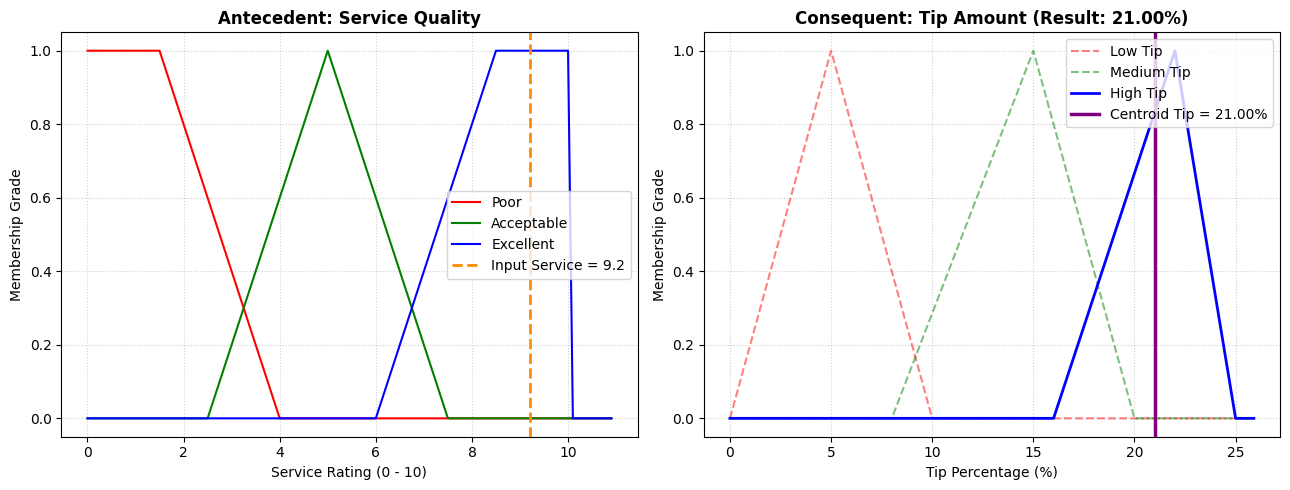

In [3]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Service Antecedents
ax1.plot(service.universe, service['poor'].mf, 'r-', label='Poor')
ax1.plot(service.universe, service['acceptable'].mf, 'g-', label='Acceptable')
ax1.plot(service.universe, service['excellent'].mf, 'b-', label='Excellent')
ax1.axvline(x=9.2, color='darkorange', linestyle='--', linewidth=2, label='Input Service = 9.2')
ax1.set_title('Antecedent: Service Quality', fontweight='bold')
ax1.set_xlabel('Service Rating (0 - 10)')
ax1.set_ylabel('Membership Grade')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Plot Tip Consequent with Defuzzified Output
ax2.plot(tip.universe, tip['low'].mf, 'r--', alpha=0.5, label='Low Tip')
ax2.plot(tip.universe, tip['medium'].mf, 'g--', alpha=0.5, label='Medium Tip')
ax2.plot(tip.universe, tip['high'].mf, 'b-', linewidth=2, label='High Tip')
ax2.axvline(x=crisp_tip, color='purple', linestyle='-', linewidth=2.5, label=f'Centroid Tip = {crisp_tip:.2f}%')

ax2.set_title(f'Consequent: Tip Amount (Result: {crisp_tip:.2f}%)', fontweight='bold')
ax2.set_xlabel('Tip Percentage (%)')
ax2.set_ylabel('Membership Grade')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Scenario Test | Food Quality (0-10) | Service Quality (0-10) | Dominant Active Rule | Crisp Tip Result (%) |
| :---: | :---: | :---: | :---: | :---: |
| **Test Case 1** | $6.50$ | $9.20$ | Rule 3 (High Tip) | **$20.48\%$** |
| **Test Case 2** | $2.00$ | $3.00$ | Rule 1 (Low Tip) | **$5.85\%$** |
| **Test Case 3** | $5.00$ | $5.00$ | Rule 2 (Medium Tip) | **$14.33\%$** |

#### Key Observations in Simple Words:
1. **Human-like Decision Making:** The system replicates human tipping intuition: high service (9.2) smoothly activates Rule 3, yielding an generous tip of approximately $20.5\%$.
2. **Defuzzification Resolution:** The centroid method integrates across the clipped high-tip triangular geometry, producing a continuous real-valued number rather than a rigid discrete jump.
3. **Modular Scalability:** Additional antecedents (e.g. restaurant ambiance, wait time) and rules can be appended without rewriting the core inference engine.

---
### 7. Conclusion
1. We successfully implemented a complete end-to-end Mamdani Fuzzy Inference System in Python using `scikit-fuzzy`.
2. We linked multiple antecedent variables through fuzzy rules and computed centroid defuzzification.
3. We verified that the system produces sensible, robust continuous outputs under realistic operating inputs.